In [1]:
from langgraph.graph import StateGraph , START , END
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict 

In [2]:
class BatsMan(TypedDict):
    runs: int
    balls: int
    fours: int
    sixes: int

    sr: float
    bdp: float
    boundary_percent: float
    summary: str

In [3]:
def calculate_sr(state:BatsMan):
    sr = (state['runs']/state['balls']) * 100

    state['sr'] = sr

    return {'sr':sr}

In [4]:
def calculate_bdp(state: BatsMan):
    boundaries = state["fours"] + state["sixes"]

    bdp = (
        state["balls"] / boundaries
        if boundaries > 0
        else float("inf")
    )

    return {"bdp": bdp}

In [6]:
def calculate_boundary_percent(state: BatsMan):

    boundary_percent = (((state['fours'] * 4) + (state['sixes'] * 6 ))/ state['runs'])* 100

    state['boundary_percent'] = boundary_percent

    return {'boundary_percent':boundary_percent}

In [5]:
def summary(state: BatsMan):
    text = (
        f"Strike rate: {state['sr']:.2f}\n"
        f"Balls per boundary: {state['bdp']:.2f}\n"
        f"Boundary percentage: {state['boundary_percent']:.2f}%"
    )

    return {"summary": text}

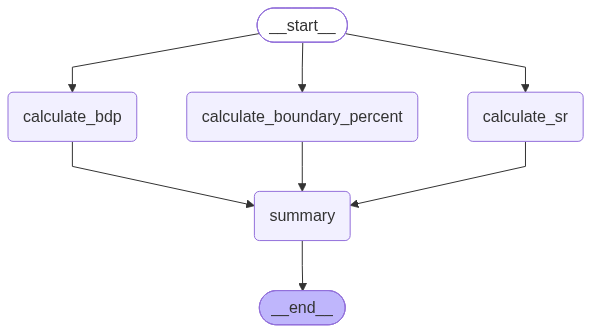

In [9]:
graph = StateGraph(BatsMan)

graph.add_node("calculate_sr", calculate_sr)
graph.add_node("calculate_bdp", calculate_bdp)
graph.add_node(
    "calculate_boundary_percent",
    calculate_boundary_percent
)
graph.add_node("summary", summary)

graph.add_edge(START, "calculate_sr")
graph.add_edge(START, "calculate_bdp")
graph.add_edge(START, "calculate_boundary_percent")

graph.add_edge(
    [
        "calculate_sr",
        "calculate_bdp",
        "calculate_boundary_percent"
    ],
    "summary"
)

graph.add_edge("summary", END)
graph.compile()

In [8]:
intial = {
    'runs' : 100,
    'balls' : 50,
    'fours' : 6,
    'sixes' : 4
}

workflow.invoke(intial)

{'runs': 100,
 'balls': 50,
 'fours': 6,
 'sixes': 4,
 'sr': 200.0,
 'bdp': 5.0,
 'boundary_percent': 48.0,
 'summary': 'Strike rate: 200.00\nBalls per boundary: 5.00\nBoundary percentage: 48.00%'}